11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9176 - loss: 0.2864 - val_accuracy: 0.9533 - val_loss: 0.1587
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9615 - loss: 0.1306 - val_accuracy: 0.9657 - val_loss: 0.1151
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9739 - loss: 0.0885 - val_accuracy: 0.9670 - val_loss: 0.1078
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9802 - loss: 0.0649 - val_accuracy: 0.9713 - val_loss: 0.0956
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9845 - loss: 0.0507 - val_accuracy: 0.9740 - val_loss: 0.0848
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9875 - loss: 0.0400 - val_accuracy: 0.9740 - val_loss: 0.0900
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9908 - loss: 0.0304 - val_accuracy: 0.9730 - val_loss: 0.0976
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━

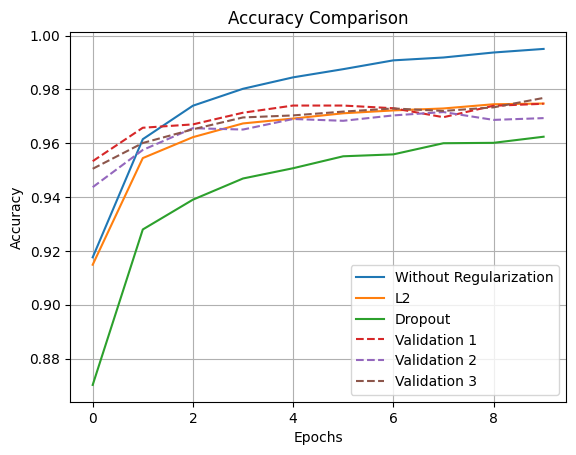

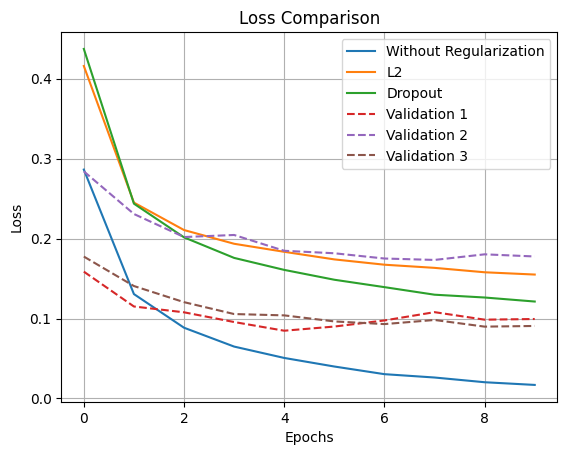

In [6]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize data
X_train = X_train / 255.0
X_test = X_test / 255.0

# Model 1: Without Regularization
model1 = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model1.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

h1 = model1.fit(X_train, y_train, epochs=10,
                validation_split=0.2)

# Model 2: L2 Regularization
model2 = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu', kernel_regularizer=l2(0.001)),
    Dense(10, activation='softmax')
])

model2.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

h2 = model2.fit(X_train, y_train, epochs=10,
                validation_split=0.2)

# Model 3: Dropout
model3 = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model3.compile(optimizer='adam',
               loss='sparse_categorical_crossentropy',
               metrics=['accuracy'])

h3 = model3.fit(X_train, y_train, epochs=10,
                validation_split=0.2)

# Evaluate models
print("Model 1 Accuracy:", model1.evaluate(X_test, y_test)[1])
print("Model 2 Accuracy:", model2.evaluate(X_test, y_test)[1])
print("Model 3 Accuracy:", model3.evaluate(X_test, y_test)[1])

# Accuracy curves
plt.plot(h1.history['accuracy'], label='Without Regularization')
plt.plot(h2.history['accuracy'], label='L2')
plt.plot(h3.history['accuracy'], label='Dropout')

plt.plot(h1.history['val_accuracy'], '--', label='Validation 1')
plt.plot(h2.history['val_accuracy'], '--', label='Validation 2')
plt.plot(h3.history['val_accuracy'], '--', label='Validation 3')

plt.title("Accuracy Comparison")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()
plt.show()

# Loss curves
plt.plot(h1.history['loss'], label='Without Regularization')
plt.plot(h2.history['loss'], label='L2')
plt.plot(h3.history['loss'], label='Dropout')

plt.plot(h1.history['val_loss'], '--', label='Validation 1')
plt.plot(h2.history['val_loss'], '--', label='Validation 2')
plt.plot(h3.history['val_loss'], '--', label='Validation 3')

plt.title("Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid()
plt.show()